# TF04 — 和歌を詠む小さな GPT を、LoRA で俳句（五七五）に変える

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ilu-h-bando/dl-tutorial/blob/main/finetuning/TF04_tiny_gpt_waka_lora.ipynb)

`TF01_tiny_gpt_waka.ipynb` の **1段の小さな GPT** に八代集の和歌（五・七・五・七・七）を学習させたあと、
**本体の重みは固定したまま**、ごく小さな追加の行列（**LoRA**）だけを松尾芭蕉の句で学習します。
同じ書き出しの5音から詠ませると、**和歌（5句）だったものが俳句（3句で終わる）に変わるか**を、音数の自動判定で確かめます。
PyTorch などのフレームワークは使いません。必要なのは **NumPy と Matplotlib だけ** です。

## このノートで体験すること
- TF01 と同じモデルで和歌を学習する（**事前学習**）。
- 俳句に出てくる新しい文字（濁点の字・「ゃゅょゎっ」・「ん」）のために、**語彙を広げる**（Embedding 表と出力層に行・列を足す）。
- **LoRA**：`W` は固定し、`W + (α/r)·A·B` の `A`（64×r）と `B`（r×64）だけを学習する。
- LoRA の**前・後・外したとき**で、出てくる詩の形（和歌／俳句／その他）の割合を比べる。

| | 事前学習（TF01 と同じ） | LoRA による追加学習 |
|---|---|---|
| データ | 八代集の和歌 約5,600首 | 芭蕉の句（5-7-5）約850句 |
| 学習する重み | 全部（約7万個） | LoRA の A・B と、新しい文字の行・列だけ |
| 本体の重み | 学習する | **固定**（変えない） |

## 動かし方

- **Google Colab**：上の「Open in Colab」バッジ →「ランタイム > すべてのセルを実行」
- **手元の Jupyter**：上から順にセルを実行

インターネット接続が必要です（和歌は Wikisource から、俳句の読みのファイルは GitHub から取得します）。
事前学習は CPU で約2分、LoRA の学習は約1分です。事前学習の結果は `tf04_base_waka.npz` に保存し、次回から読み込みます。

### 俳句のデータについて
- 本文：松尾芭蕉『芭蕉俳句全集』大塚甲山 編（1903年）、[Wikisource](https://ja.wikisource.org/wiki/芭蕉俳句全集)（CC BY-SA 4.0）
- **読み（ひらがな）は AI（Claude Opus 5.5）が歴史的仮名遣いで付けたもので、誤りを含む可能性があります。**
- ファイル `芭蕉俳句全集.txt` は「原文 TAB 読み（TAB 印）」の形です。印のない 5-7-5 の句だけを使います
  （「字」＝字余り、「△」＝読みに自信がない句は使いません）。

## 1. 設定

In [1]:
import numpy as np
import re, json, time, unicodedata, urllib.request, urllib.parse
from pathlib import Path
import matplotlib.pyplot as plt

# ---- モデルの大きさ（TF01 と同じ） ----
CTX    = 48
D      = 64
N_HEAD = 4
D_FF   = 256
HD     = D // N_HEAD
USE_MASK = True

# ---- 事前学習（和歌）：TF01 と同じ設定 ----
BASE_STEPS   = 3000
BATCH        = 32
LR           = 3e-3
WEIGHT_DECAY = 0.01
DROPOUT      = 0.1
BASE_FILE    = Path('tf04_base_waka.npz')   # 事前学習の結果。消すと学習し直す

# ---- LoRA による追加学習（俳句） ----
LORA_RANK    = 4                # r：A は 64×r、B は r×64
LORA_ALPHA   = 8                # 倍率 α/r をかけて足す
LORA_TARGETS = ('Wq', 'Wv')     # LoRA を付ける行列（'Wk','Wo','Wg','Wu','Wd' も指定できる）
LORA_STEPS   = 1500
LORA_LR      = 3e-3

TARGET_WAKA  = [5, 7, 5, 7, 7]
TARGET_HAIKU = [5, 7, 5]
HAIKU_FILE = Path('芭蕉俳句全集.txt')
HAIKU_URL  = ('https://raw.githubusercontent.com/ilu-h-bando/dl-tutorial/main/finetuning/'
              + urllib.parse.quote('芭蕉俳句全集.txt'))
SEED = 0

## 2. 和歌のデータ（TF01 と同じ）

Wikisource の八代集から、ひらがなの読みが 5-7-5-7-7 の歌だけを取り出します。
音数は、小さい「ゃゅょ」などを前の文字と合わせて1音と数えます（TF01 と同じ `morae`）。

In [2]:
API = "https://ja.wikisource.org/w/api.php"
ANTHOLOGIES = ["古今和歌集", "後撰和歌集", "拾遺和歌集", "千載和歌集", "新古今和歌集"]
HEADERS = {"User-Agent": "tiny-gpt-tutorial/1.0 (ILU deep learning lecture; https://github.com/ilu-h-bando/dl-tutorial)"}

def api_get(**params):
    url = API + "?" + urllib.parse.urlencode({**params, "format": "json", "formatversion": "2"})
    with urllib.request.urlopen(urllib.request.Request(url, headers=HEADERS), timeout=60) as r:
        return json.loads(r.read().decode("utf-8"))

def load_anthology(name):
    q = api_get(action="query", list="allpages", apprefix=name + "/巻", aplimit=50)
    titles = [p["title"] for p in q["query"]["allpages"]]
    pages = api_get(action="query", prop="revisions", rvprop="content", rvslots="main", titles="|".join(titles))
    return {p["title"]: p["revisions"][0]["slots"]["main"]["content"] for p in pages["query"]["pages"]}

SMALL = set("ぁぃぅぇぉゃゅょゎ")
def morae(s):
    """音数：小さい「ゃゅょ」などは前の文字と合わせて 1 音"""
    return sum(1 for c in s if c not in SMALL)

def parse_poems(wikitext):
    poems = []
    for body in re.split(r'<span id="\d+">\d+</span>', wikitext)[1:]:
        for line in body.split("\n"):
            line = line.strip()
            if "－" in line and re.fullmatch(r"[ぁ-ゖ－]+", line):
                segs = line.split("－")
                if [morae(s) for s in segs] == TARGET_WAKA:
                    poems.append(segs)
                break
    return poems

try:
    wikitext = {name: load_anthology(name) for name in ANTHOLOGIES}
except Exception as e:
    raise RuntimeError("Wikisource からの取得に失敗しました。ネットワークを確認して、もう一度このセルを実行してください: " + str(e))

waka, seen = [], set()
for name, pages in wikitext.items():
    for wt in pages.values():
        for segs in parse_poems(wt):
            if tuple(segs) not in seen:
                seen.add(tuple(segs)); waka.append(segs)
print("和歌（5-7-5-7-7）:", len(waka), "首")
for segs in waka[:2]:
    print("  ", "／".join(segs))

和歌（5-7-5-7-7）: 5652 首
   そてひちて／むすひしみつの／こほれるを／はるたつけふの／かせやとくらむ
   はるかすみ／たてるやいつこ／みよしのの／よしののやまに／ゆきはふりつつ


## 3. 俳句のデータ：芭蕉の句

`芭蕉俳句全集.txt` を読み込み、印のない（5-7-5 の）句だけを使います。
手元にファイルがなければ GitHub から取得します。

和歌のデータとの大きな違いは、**俳句の読みには濁点がある**ことです（和歌の読みは昔の表記のため濁点がありません）。

In [3]:
if not HAIKU_FILE.is_file():
    print("download:", HAIKU_URL)
    req = urllib.request.Request(HAIKU_URL, headers=HEADERS)
    with urllib.request.urlopen(req, timeout=60) as r:
        HAIKU_FILE.write_bytes(r.read())

haiku, marks = [], {}
for line in HAIKU_FILE.read_text(encoding="utf-8").splitlines():
    if not line.strip():
        continue
    cols = line.split("\t")
    mark = cols[2].strip() if len(cols) > 2 else ""
    marks[mark] = marks.get(mark, 0) + 1
    if mark:                                   # 「字」「△」の句は使わない
        continue
    segs = cols[1].strip().split("／")
    if [morae(s) for s in segs] == TARGET_HAIKU:
        haiku.append(segs)
print("ファイルの句の数:", sum(marks.values()), "/ 印ごと:", {k or "印なし": v for k, v in marks.items()})
print("使う俳句（5-7-5）:", len(haiku), "句")
for segs in haiku[:3]:
    print("  ", "／".join(segs))

ファイルの句の数: 1322 / 印ごと: {'印なし': 944, '△': 195, '字': 183}
使う俳句（5-7-5）: 944 句
   はるたつて／まだここのかの／のやまかな
   しゃうぐゎつも／みのとあふみや／うるふづき
   こぞははや／そこへすされよ／たらうづき


## 4. 語彙を広げる：入力と出力のベクトルを足す

文字ごとに番号（トークン ID）を振るのは TF01 と同じです。まず和歌の文字だけで語彙を作り、事前学習に使います。
俳句には、和歌に**一度も出てこない文字**があります。

- 濁点・半濁点の字（が・ぎ…ぽ）
- 小さい「ゃ ゅ ょ ゎ っ」（例：しゃうぐゎつ ＝ 正月）
- 「ん」（和歌の読みでは「む」と書かれている）

これらは、事前学習のモデルの **Embedding 表（入力：語彙数 × 64）と出力層（64 × 語彙数）に行・列が存在しません**。
そこで、和歌の語彙の**後ろに**新しい文字を足します（和歌の文字の番号は変えません）。

新しい文字の始め方は、入力側と出力側で変えます。
- **入力側（Embedding の行）**：**元になる文字のベクトルを写します**（「が」←「か」、「ゃ」←「や」、「ん」←「む」、「っ」←「つ」）。
  書き出しに「が」が入っても、最初から「か」とほぼ同じ意味として読めます。
- **出力側（出力層の列）**：**0 から始めます**。元の字の列を写すと「か」と「が」が同じ得点になり、学習前のモデルが濁点の字をでたらめに出してしまうためです。
  0 なら得点はいつも 0 で、学習前はほとんど選ばれません。

In [4]:
SEP, END = "／", "\n"
def poem_text(segs):
    return SEP.join(segs) + END

def split_train_val(poems, seed):
    order = np.random.default_rng(seed).permutation(len(poems))
    n_val = len(poems) // 10
    return [poems[i] for i in order[n_val:]], [poems[i] for i in order[:n_val]]

waka_train, waka_val = split_train_val(waka, 0)
haiku_train, haiku_val = split_train_val(haiku, 1)

base_chars = sorted(set("".join(poem_text(p) for p in waka)))          # 事前学習の語彙
haiku_text_all = "".join(poem_text(p) for p in haiku)
new_chars = sorted(set(haiku_text_all) - set(base_chars))              # 俳句で増える文字
chars = base_chars + new_chars                                          # 広げた語彙（和歌の番号はそのまま）
V0, V = len(base_chars), len(chars)
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
def encode(s):  return [stoi[c] for c in s if c in stoi]
def decode(ids): return "".join(itos[i] for i in ids)

SMALL2BIG = str.maketrans("ぁぃぅぇぉゃゅょゎっ", "あいうえおやゆよわつ")
def base_char(c):
    """新しい文字の『元になる文字』：濁点を外す・小書きを大きく・ん→む"""
    b = "".join(x for x in unicodedata.normalize("NFD", c) if x not in "\u3099\u309a")
    b = unicodedata.normalize("NFC", b).translate(SMALL2BIG)
    return "む" if b == "ん" else b

count = {c: haiku_text_all.count(c) for c in new_chars}
print(f"事前学習の語彙 V0 = {V0}（ひらがな {V0 - 2} ＋ 区切り「／」と改行）")
print(f"俳句で増える文字 {len(new_chars)} 種類 → 広げた語彙 V = {V}")
print("新しい文字（元になる文字・俳句での回数）:")
print("  " + "  ".join(f"{c}←{base_char(c)}:{count[c]}" for c in new_chars))
assert all(base_char(c) in base_chars for c in new_chars)

waka_tr = np.array(encode("".join(poem_text(p) for p in waka_train)), dtype=np.int64)
waka_va = np.array(encode("".join(poem_text(p) for p in waka_val)), dtype=np.int64)
haiku_tr = np.array(encode("".join(poem_text(p) for p in haiku_train)), dtype=np.int64)
haiku_va = np.array(encode("".join(poem_text(p) for p in haiku_val)), dtype=np.int64)
print(f"\n和歌 訓練 {len(waka_train)} 首 / 検証 {len(waka_val)} 首、俳句 訓練 {len(haiku_train)} 句 / 検証 {len(haiku_val)} 句")

事前学習の語彙 V0 = 49（ひらがな 47 ＋ 区切り「／」と改行）
俳句で増える文字 30 種類 → 広げた語彙 V = 79
新しい文字（元になる文字・俳句での回数）:
  が←か:191  ぎ←き:117  ぐ←く:87  げ←け:64  ご←こ:59  ざ←さ:63  じ←し:67  ず←す:66  ぜ←せ:42  ぞ←そ:23  だ←た:110  ぢ←ち:39  っ←つ:14  づ←つ:114  で←て:62  ど←と:107  ば←は:137  ぱ←は:1  び←ひ:91  ぴ←ひ:1  ぶ←ふ:72  べ←へ:25  ぺ←へ:1  ぼ←ほ:39  ぽ←ほ:3  ゃ←や:58  ゅ←ゆ:12  ょ←よ:4  ゎ←わ:15  ん←む:167

和歌 訓練 5087 首 / 検証 565 首、俳句 訓練 850 句 / 検証 94 句


## 5. モデル（TF01 と同じ部品）

切り出し・位置エンコーディング・Attention・SwiGLU MLP・LayerNorm・順伝播・逆伝播は TF01 と同じです。
学習データは、いつも**詩の頭（改行の位置）から**切り出します（TF01 の `ALIGN_TO_POEM = True`）。
語彙数は、パラメータの形（`E` の行数）から決めるようにしたので、語彙を広げたモデルにもそのまま使えます。

In [5]:
def get_batch(d, batch, rng):
    starts = np.where(d == stoi[END])[0]
    starts = starts[starts + CTX + 1 < len(d)]
    ix = rng.choice(starts, batch)
    x = np.stack([d[i:i + CTX] for i in ix])
    y = np.stack([d[i + 1:i + CTX + 1] for i in ix])
    return x, y

def pos_encoding(n, d):
    pos = np.arange(n)[:, None]
    i = np.arange(d // 2)[None, :]
    ang = pos / (10000 ** (2 * i / d))
    pe = np.zeros((n, d))
    pe[:, 0::2] = np.sin(ang)
    pe[:, 1::2] = np.cos(ang)
    return pe

def softmax(x):
    e = np.exp(x - x.max(-1, keepdims=True))
    return e / e.sum(-1, keepdims=True)

def attn_f(x, P, causal=True):
    B, L, _ = x.shape
    dt = x.dtype.type
    split = lambda t: t.reshape(B, L, N_HEAD, HD).transpose(0, 2, 1, 3)
    q = split(x @ P["Wq"]); k = split(x @ P["Wk"]); v = split(x @ P["Wv"])
    sc = q @ k.transpose(0, 1, 3, 2) * dt(1 / np.sqrt(HD))
    if causal:
        sc = np.where(np.triu(np.ones((L, L), dtype=bool), 1), dt(-1e9), sc)
    A = softmax(sc)
    o = (A @ v).transpose(0, 2, 1, 3).reshape(B, L, D)
    return o @ P["Wo"], (x, q, k, v, A, o)

def ffn_f(x, P):
    a = x @ P["Wg"]; b = x @ P["Wu"]
    sg = 1 / (1 + np.exp(-a)); s_ = a * sg; h = s_ * b
    return h @ P["Wd"], (x, a, b, sg, s_, h)

def ln_f(x, g, b):
    mu = x.mean(-1, keepdims=True); var = x.var(-1, keepdims=True)
    inv = 1 / np.sqrt(var + 1e-5); xh = (x - mu) * inv
    return xh * g + b, (xh, inv, g)

def init_params(vocab, seed=0, dtype=np.float32):
    r = np.random.default_rng(seed)
    n = lambda *shape: r.normal(0, 0.02, shape)
    P = {"E": n(vocab, D), "ln1_g": np.ones(D), "ln1_b": np.zeros(D),
         "Wq": n(D, D), "Wk": n(D, D), "Wv": n(D, D), "Wo": n(D, D),
         "ln2_g": np.ones(D), "ln2_b": np.zeros(D),
         "Wg": n(D, D_FF), "Wu": n(D, D_FF), "Wd": n(D_FF, D),
         "lnf_g": np.ones(D), "lnf_b": np.zeros(D), "Wout": n(D, vocab)}
    return {k: v.astype(dtype) for k, v in P.items()}

def make_dropout(shape, rate, rng, dtype):
    if rate == 0 or rng is None:
        return None
    return (rng.random(shape) >= rate).astype(dtype) / dtype(1 - rate)

def forward(P, x_ids, y_ids=None, rng=None, dropout=0.0):
    B, L = x_ids.shape
    Vp = P["E"].shape[0]
    dt = P["E"].dtype.type
    m0, m1, m2 = (make_dropout((B, L, D), dropout, rng, dt) for _ in range(3))
    h0 = P["E"][x_ids] + pos_encoding(L, D).astype(dt)
    if m0 is not None: h0 = h0 * m0
    n1, c_ln1 = ln_f(h0, P["ln1_g"], P["ln1_b"])
    ao, c_att = attn_f(n1, P, causal=USE_MASK)
    if m1 is not None: ao = ao * m1
    h1 = h0 + ao
    n2, c_ln2 = ln_f(h1, P["ln2_g"], P["ln2_b"])
    mo, c_ffn = ffn_f(n2, P)
    if m2 is not None: mo = mo * m2
    h2 = h1 + mo
    nf, c_lnf = ln_f(h2, P["lnf_g"], P["lnf_b"])
    logits = nf @ P["Wout"]
    p = softmax(logits)
    cache = dict(x_ids=x_ids, y_ids=y_ids, masks=(m0, m1, m2), c_ln1=c_ln1, c_att=c_att,
                 c_ln2=c_ln2, c_ffn=c_ffn, nf=nf, c_lnf=c_lnf, p=p)
    if y_ids is None:
        return logits, cache
    loss = -np.log(p.reshape(-1, Vp)[np.arange(B * L), y_ids.reshape(-1)] + 1e-12).mean()
    return loss, cache

def ln_b(dy, c):
    xh, inv, g = c
    dg = (dy * xh).sum((0, 1)); db = dy.sum((0, 1)); dxh = dy * g
    dx = inv * (dxh - dxh.mean(-1, keepdims=True) - xh * (dxh * xh).mean(-1, keepdims=True))
    return dx, dg, db

def lin_b(dy, x, W):
    x2 = x.reshape(-1, x.shape[-1]); d2 = dy.reshape(-1, dy.shape[-1])
    return (d2 @ W.T).reshape(x.shape), x2.T @ d2

def attn_b(dout, P, c):
    x, q, k, v, A, o = c
    B, L, _ = x.shape
    dt = x.dtype.type
    g = {}
    do, g["Wo"] = lin_b(dout, o, P["Wo"])
    do = do.reshape(B, L, N_HEAD, HD).transpose(0, 2, 1, 3)
    dA = do @ v.transpose(0, 1, 3, 2)
    dv = A.transpose(0, 1, 3, 2) @ do
    dsc = A * (dA - (dA * A).sum(-1, keepdims=True)) * dt(1 / np.sqrt(HD))
    dq = dsc @ k; dk = dsc.transpose(0, 1, 3, 2) @ q
    merge = lambda t: t.transpose(0, 2, 1, 3).reshape(B, L, D)
    dxq, g["Wq"] = lin_b(merge(dq), x, P["Wq"])
    dxk, g["Wk"] = lin_b(merge(dk), x, P["Wk"])
    dxv, g["Wv"] = lin_b(merge(dv), x, P["Wv"])
    return dxq + dxk + dxv, g

def ffn_b(dout, P, c):
    x, a, b, sg, s_, h = c
    g = {}
    dh, g["Wd"] = lin_b(dout, h, P["Wd"])
    ds, db = dh * b, dh * s_
    da = ds * (sg * (1 + a * (1 - sg)))
    dxa, g["Wg"] = lin_b(da, x, P["Wg"])
    dxb, g["Wu"] = lin_b(db, x, P["Wu"])
    return dxa + dxb, g

def backward(P, cache):
    x_ids, y_ids, (m0, m1, m2) = cache["x_ids"], cache["y_ids"], cache["masks"]
    B, L = x_ids.shape
    Vp = P["E"].shape[0]
    G = {}
    dl = cache["p"].copy().reshape(-1, Vp)
    dl[np.arange(B * L), y_ids.reshape(-1)] -= 1
    dl = (dl / (B * L)).reshape(B, L, Vp)
    dnf, G["Wout"] = lin_b(dl, cache["nf"], P["Wout"])
    dh2, G["lnf_g"], G["lnf_b"] = ln_b(dnf, cache["c_lnf"])
    dmo = dh2 * m2 if m2 is not None else dh2
    dn2, gf = ffn_b(dmo, P, cache["c_ffn"]); G.update(gf)
    dh1_ln, G["ln2_g"], G["ln2_b"] = ln_b(dn2, cache["c_ln2"])
    dh1 = dh2 + dh1_ln
    dao = dh1 * m1 if m1 is not None else dh1
    dn1, ga = attn_b(dao, P, cache["c_att"]); G.update(ga)
    dh0_ln, G["ln1_g"], G["ln1_b"] = ln_b(dn1, cache["c_ln1"])
    dh0 = dh1 + dh0_ln
    if m0 is not None: dh0 = dh0 * m0
    G["E"] = np.zeros_like(P["E"])
    np.add.at(G["E"], x_ids, dh0)
    return G

## 6. 詩を詠む部品と、形の判定

書き出し（ひらがな）を `／` で区切った形に整え、続きを1文字ずつ作ります（TF01 の `generate_waka` と同じ考え方）。
TF04 では濁点を**外しません**（俳句の読みには濁点があるため）。モデルの語彙にない文字は無視します。

できた詩の形を、句の数と音数で判定します。
- **俳句**：3句で 5-7-5 で終わった
- **和歌**：5句で 5-7-5-7-7
- **その他**：どちらでもない（途中で音数がずれたなど）

In [6]:
def to_hiragana(s):
    return "".join(chr(ord(c) - 0x60) if "ァ" <= c <= "ヶ" else c for c in s)

def format_prompt(kana, target):
    """書き出しを 5・7 音ごとに区切る（最後の句の手前まで）"""
    chars_ = [c for c in kana if c not in "／－/ 　\n"]
    segs, cur = [], ""
    for c in chars_:
        if c not in SMALL and len(segs) < len(target) - 1 and cur and morae(cur) >= target[len(segs)]:
            segs.append(cur); cur = ""
        cur += c
    if len(segs) < len(target) - 1 and cur and morae(cur) == target[len(segs)]:
        segs.append(cur); cur = ""
    body = SEP.join(segs + ([cur] if cur else []))
    return body + SEP if (not cur and segs) else body

def generate(P, kana, target=TARGET_HAIKU, temperature=0.7, top_k=8, seed=None, max_len=60):
    r = np.random.default_rng(seed)
    Vp = P["E"].shape[0]
    kana = to_hiragana(kana)
    usable = [c for c in kana if c in stoi and stoi[c] < Vp]
    ids = encode(END + format_prompt("".join(usable), target))
    for _ in range(max_len):
        logits, _ = forward(P, np.array(ids[-CTX:])[None])
        lg = logits[0, -1] / max(temperature, 1e-6)
        if top_k:
            th = np.sort(lg)[-top_k]
            lg = np.where(lg < th, -1e9, lg)
        nxt = int(r.choice(Vp, p=softmax(lg)))
        if nxt == stoi[END]:
            break
        ids.append(nxt)
    return decode(ids[1:])

def form_of(text):
    m = [morae(s) for s in text.strip(END).split(SEP)]
    if m == TARGET_HAIKU: return "haiku"
    if m == TARGET_WAKA:  return "waka"
    return "other"

LABEL = {"haiku": "俳句", "waka": "和歌", "other": "その他"}
def show(text):
    return f"{text}   [{LABEL[form_of(text)]}] 音数 " + "-".join(str(morae(s)) for s in text.split(SEP))

## 7. 事前学習：和歌を学ぶ（TF01 と同じ）

和歌の語彙（`V0` 文字）だけのモデルを、TF01 と同じ設定で学習します。全部の重み（約7万個）を学習します。
保存ファイル `tf04_base_waka.npz` があり、語彙が同じなら、学習せずに読み込みます。

In [7]:
def adamw_step(P, G, state, step, lr, decay_keys):
    gn = np.sqrt(sum((g.astype(np.float64) ** 2).sum() for g in G.values()))
    scale = min(1.0, 1.0 / (gn + 1e-6))                     # 勾配クリッピング
    for k in G:
        m, v = state.setdefault(k, (np.zeros_like(P[k]), np.zeros_like(P[k])))
        g = G[k] * scale
        m = 0.9 * m + 0.1 * g; v = 0.999 * v + 0.001 * g * g
        state[k] = (m, v)
        mh, vh = m / (1 - 0.9 ** step), v / (1 - 0.999 ** step)
        if k in decay_keys:
            P[k] -= lr * WEIGHT_DECAY * P[k]
        P[k] -= lr * mh / (np.sqrt(vh) + 1e-8)

def eval_loss(P, data, n=4):
    r = np.random.default_rng(123)
    return float(np.mean([forward(P, *get_batch(data, 32, r))[0] for _ in range(n)]))

def train_base():
    P = init_params(V0, seed=SEED)
    state, rng, t0 = {}, np.random.default_rng(SEED), time.time()
    decay = {k for k in P if P[k].ndim == 2 and k != "E"}
    run = []
    for step in range(1, BASE_STEPS + 1):
        lr = LR * min(1, step / 100) * (0.1 + 0.9 * 0.5 * (1 + np.cos(np.pi * step / BASE_STEPS)))
        loss, cache = forward(P, *get_batch(waka_tr, BATCH, rng), rng=rng, dropout=DROPOUT)
        adamw_step(P, backward(P, cache), state, step, lr, decay)
        run.append(float(loss))
        if step % 500 == 0 or step == 1:
            print(f"step {step:5d}  loss {np.mean(run):.3f}  val {eval_loss(P, waka_va):.3f}  ({time.time() - t0:.0f}秒)")
            run = []
    return P

loaded = False
if BASE_FILE.is_file():
    z = np.load(BASE_FILE, allow_pickle=False)
    if list(z["vocab"]) == base_chars:
        P_base = {k: z[k] for k in z.files if k != "vocab"}
        loaded = True
        print("事前学習の結果を読み込みました:", BASE_FILE)
if not loaded:
    P_base = train_base()
    np.savez(BASE_FILE, vocab=np.array(base_chars), **P_base)
    print("保存しました:", BASE_FILE)

N_BASE = sum(v.size for v in P_base.values())
print(f"事前学習モデルのパラメータ数: {N_BASE:,}（語彙 {V0}）")
for i, kana in enumerate(["はるかすみ", "あきのよの"]):
    print("  ", show(generate(P_base, kana, TARGET_WAKA, seed=i)))

step     1  loss 3.898  val 3.898  (0秒)


step   500  loss 2.912  val 2.591  (16秒)


step  1000  loss 2.572  val 2.450  (32秒)


step  1500  loss 2.438  val 2.350  (48秒)


step  2000  loss 2.358  val 2.305  (63秒)


step  2500  loss 2.317  val 2.279  (80秒)


step  3000  loss 2.297  val 2.268  (97秒)
保存しました: tf04_base_waka.npz
事前学習モデルのパラメータ数: 72,192（語彙 49）
   はるかすみ／こころにしらぬ／かりにかは／たかまのかけに／こひしかるるる   [和歌] 音数 5-7-5-7-7
   あきのよの／かみにもあらは／かけにけり／いつかところも／おもほゆるかな   [和歌] 音数 5-7-5-7-7


## 8. LoRA を付ける

LoRA（Low-Rank Adaptation）は、学習済みの重み `W`（64×64）を**変えずに**、小さな2つの行列の積を足します。

```
W' = W + (α / r) · A · B        A：64 × r、B：r × 64（r = 4 なら 64×4 と 4×64）
```

- 学習するのは `A` と `B` だけです。r = 4 なら 1 つの行列につき 64×4 + 4×64 = **512 個**（`W` は 4,096 個）。
- `B` を 0 で始めるので、学習を始める前は `W' = W`（元のモデルとまったく同じ）です。
- `A・B` の積は「64×64 だが、自由度は r しかない」変化になります（**低ランク**）。
- 学習後に `A・B` を取り除けば、**いつでも元のモデルに戻せます**。

加えて、4章で足した**新しい文字の行（Embedding）と列（出力層）**も学習します。元からある `V0` 文字の行・列は固定のままです。

In [8]:
def init_lora(seed=SEED):
    r = np.random.default_rng(seed)
    L = {}
    for t in LORA_TARGETS:
        d_in, d_out = P_base[t].shape
        L[t + "_A"] = r.normal(0, 1 / np.sqrt(d_in), (d_in, LORA_RANK)).astype(np.float32)
        L[t + "_B"] = np.zeros((LORA_RANK, d_out), dtype=np.float32)      # 0 で始める → 最初は元のモデルと同じ
    src = [stoi[base_char(c)] for c in new_chars]                          # 新しい文字の行・列は、元の文字から写す
    L["E_new"] = P_base["E"][src].copy()
    L["Wout_new"] = np.zeros((D, len(new_chars)), dtype=np.float32)       # 出力側は 0 から（学習前はほとんど出さない）
    return L

LORA_SCALE = LORA_ALPHA / LORA_RANK

def merged(L, use_lora=True):
    """事前学習の重み + LoRA（＋新しい文字の行・列）をまとめた、順伝播用の重み"""
    P = dict(P_base)
    P["E"] = np.concatenate([P_base["E"], L["E_new"]], axis=0)
    P["Wout"] = np.concatenate([P_base["Wout"], L["Wout_new"]], axis=1)
    if use_lora:
        for t in LORA_TARGETS:
            P[t] = P_base[t] + LORA_SCALE * (L[t + "_A"] @ L[t + "_B"])
    return P

def lora_grads(L, G):
    """W' の勾配から、A・B と新しい行・列の勾配を作る（連鎖律）"""
    GL = {"E_new": G["E"][V0:], "Wout_new": G["Wout"][:, V0:]}
    for t in LORA_TARGETS:
        GL[t + "_A"] = LORA_SCALE * (G[t] @ L[t + "_B"].T)
        GL[t + "_B"] = LORA_SCALE * (L[t + "_A"].T @ G[t])
    return GL

L0 = init_lora()
n_lora = sum(L0[t + s].size for t in LORA_TARGETS for s in ("_A", "_B"))
n_new = L0["E_new"].size + L0["Wout_new"].size
print(f"LoRA（r={LORA_RANK}、{', '.join(LORA_TARGETS)}）: {n_lora:,} 個")
print(f"新しい文字の行・列（{len(new_chars)} 文字 × 64 × 2）: {n_new:,} 個")
print(f"学習する重みの合計: {n_lora + n_new:,} 個（事前学習モデル {N_BASE:,} 個の {100 * (n_lora + n_new) / N_BASE:.1f}%）")
print("学習前の W' と W の差:", max(float(np.abs(merged(L0)[t] - P_base[t]).max()) for t in LORA_TARGETS))

LoRA（r=4、Wq, Wv）: 1,024 個
新しい文字の行・列（30 文字 × 64 × 2）: 3,840 個
学習する重みの合計: 4,864 個（事前学習モデル 72,192 個の 6.7%）
学習前の W' と W の差: 0.0


### 勾配チェック：LoRA の A・B と新しい行・列

`A・B` の勾配は、`W'` の勾配から連鎖律で作ります（`dA = (α/r)·dW'·Bᵀ`、`dB = (α/r)·Aᵀ·dW'`）。
数値微分と一致するかを確かめます。`B` が 0 のままだと `A` の勾配も 0 になるので、確認用に `B` を小さな乱数にします。

In [9]:
P64 = {k: v.astype(np.float64) for k, v in P_base.items()}
Lc = {k: v.astype(np.float64) for k, v in init_lora(seed=1).items()}
rc = np.random.default_rng(5)
for t in LORA_TARGETS:
    Lc[t + "_B"] = rc.normal(0, 0.02, Lc[t + "_B"].shape)
_saved = P_base
P_base = P64
xb, yb = get_batch(haiku_tr, 4, np.random.default_rng(2))
_, cache = forward(merged(Lc), xb, yb)
GL = lora_grads(Lc, backward(merged(Lc), cache))
worst = 0.0
for name in Lc:
    for _ in range(2):
        if name == "E_new":
            used = [i - V0 for i in xb.ravel() if i >= V0]
            idx = (int(rc.choice(used)), int(rc.integers(D)))
        else:
            idx = tuple(int(rc.integers(s)) for s in Lc[name].shape)
        old = Lc[name][idx]; eps = 1e-5
        Lc[name][idx] = old + eps; lp, _ = forward(merged(Lc), xb, yb)
        Lc[name][idx] = old - eps; lm, _ = forward(merged(Lc), xb, yb)
        Lc[name][idx] = old
        num, ana = (lp - lm) / (2 * eps), GL[name][idx]
        rel = abs(ana - num) / (abs(ana) + abs(num) + 1e-12)
        worst = max(worst, rel)
        print(f"{name:10s} {str(idx):10s} 逆伝播 {ana: .4e}  数値微分 {num: .4e}  相対誤差 {rel:.1e}")
P_base = _saved
print("\n最大の相対誤差:", f"{worst:.1e}", "→", "一致 ✓" if worst < 1e-3 else "不一致 ✗")
assert worst < 1e-3

Wq_A       (36, 3)    逆伝播  1.1663e-03  数値微分  1.1663e-03  相対誤差 6.3e-07
Wq_A       (62, 1)    逆伝播  1.6395e-03  数値微分  1.6395e-03  相対誤差 1.6e-08
Wq_B       (3, 6)     逆伝播  1.3343e-02  数値微分  1.3343e-02  相対誤差 2.4e-06
Wq_B       (2, 22)    逆伝播 -2.3086e-02  数値微分 -2.3086e-02  相対誤差 1.2e-08
Wv_A       (54, 1)    逆伝播 -4.8341e-03  数値微分 -4.8341e-03  相対誤差 4.7e-08
Wv_A       (27, 1)    逆伝播 -5.4891e-04  数値微分 -5.4891e-04  相対誤差 1.4e-06
Wv_B       (1, 6)     逆伝播 -1.7011e-01  数値微分 -1.7011e-01  相対誤差 6.3e-07
Wv_B       (1, 56)    逆伝播  7.2297e-02  数値微分  7.2297e-02  相対誤差 9.5e-08
E_new      (10, 9)    逆伝播 -4.8108e-04  数値微分 -4.8108e-04  相対誤差 3.2e-07
E_new      (11, 46)   逆伝播 -1.0870e-03  数値微分 -1.0870e-03  相対誤差 1.0e-06
Wout_new   (2, 12)    逆伝播 -1.4470e-03  数値微分 -1.4470e-03  相対誤差 4.9e-08
Wout_new   (41, 14)   逆伝播  1.3695e-02  数値微分  1.3695e-02  相対誤差 4.8e-10

最大の相対誤差: 2.4e-06 → 一致 ✓


## 9. LoRA の学習前：書き出しを俳句にしても、和歌のまま続ける

俳句の検証用の句（学習に使わない句）の最初の5音を与えて詠ませます。
LoRA を付けた直後（`B = 0`）は元のモデルと同じなので、5句の和歌を詠もうとするはずです。

In [10]:
def form_rates(P, prompts, n_seed=2):
    cnt = {"haiku": 0, "waka": 0, "other": 0}
    for i, segs in enumerate(prompts):
        for s in range(n_seed):
            cnt[form_of(generate(P, segs[0], seed=100 * i + s))] += 1
    total = sum(cnt.values())
    return {k: 100 * v / total for k, v in cnt.items()}

P_before = merged(L0)
for i, segs in enumerate(haiku_val[:4]):
    print("原句 :", "／".join(segs))
    print("詠む :", show(generate(P_before, segs[0], seed=i)))
rate_before = form_rates(P_before, haiku_val)
print("\n形の割合（LoRA 学習前）:", {LABEL[k]: f"{v:.0f}%" for k, v in rate_before.items()})

原句 : ばせをばを／はしらにかけん／いほのつき
詠む : ばせをばを／たつたかへるる／かりにかへ／たたひのかせに／こひしかるるる   [和歌] 音数 5-7-5-7-7
原句 : ほしざきの／やみをみよとや／なくちどり
詠む : ほしざきの／こゑにもいてそ／かけにける／いつかところも／おもほゆるかな   [和歌] 音数 5-7-5-7-7
原句 : すそやまや／にじはくあとの／ゆふつつじ
詠む : すそやまや／いつのかはらに／おもふこと／おもふこころの／はるのよのつき   [和歌] 音数 5-7-5-7-7
原句 : るすにきて／たなさがしする／ふぢのはな
詠む : るすにきて／あきのなからの／たかさこの／たまのはなとか／いまはしらゆき   [和歌] 音数 5-7-5-7-7



形の割合（LoRA 学習前）: {'俳句': '0%', '和歌': '96%', 'その他': '4%'}


## 10. LoRA を学習する：芭蕉の句で

学習の流れは TF01 と同じですが、**更新するのは LoRA の `A`・`B` と新しい文字の行・列だけ**です。
事前学習の重み `P_base` は一度も変えません（最後に確かめます）。

In [11]:
L = init_lora()
P_base_check = {k: v.copy() for k, v in P_base.items()}
state, rng, t0 = {}, np.random.default_rng(SEED), time.time()
hist = {"step": [], "loss": [], "val": [], "haiku": []}
run = []
for step in range(1, LORA_STEPS + 1):
    lr = LORA_LR * min(1, step / 50) * (0.1 + 0.9 * 0.5 * (1 + np.cos(np.pi * step / LORA_STEPS)))
    P = merged(L)
    loss, cache = forward(P, *get_batch(haiku_tr, BATCH, rng), rng=rng, dropout=DROPOUT)
    adamw_step(L, lora_grads(L, backward(P, cache)), state, step, lr, decay_keys=set())
    run.append(float(loss))
    if step % 250 == 0 or step == 1:
        P = merged(L)
        h = form_rates(P, haiku_val[:30], n_seed=1)["haiku"]
        hist["step"].append(step); hist["loss"].append(float(np.mean(run)))
        hist["val"].append(eval_loss(P, haiku_va)); hist["haiku"].append(h)
        print(f"step {step:5d}  loss {np.mean(run):.3f}  val {hist['val'][-1]:.3f}  俳句の割合 {h:3.0f}%  ({time.time() - t0:.0f}秒)")
        print("     ", show(generate(P, "ふるいけや", seed=0)))
        run = []
assert all(np.array_equal(P_base[k], P_base_check[k]) for k in P_base), "事前学習の重みが変わっています"
print("事前学習の重みは変わっていません ✓")

step     1  loss 5.314  val 5.463  俳句の割合   0%  (0秒)
      ふるいけや／しけきかへりの／こゑなから／たえぬはかりそ／こひしかるれは   [和歌] 音数 5-7-5-7-7


step   250  loss 3.786  val 3.328  俳句の割合  67%  (7秒)
      ふるいけや／たちかきりやは／こがな   [その他] 音数 5-7-3


step   500  loss 3.235  val 3.242  俳句の割合  63%  (18秒)
      ふるいけや／たつきかはらの／こりにある   [俳句] 音数 5-7-5


step   750  loss 3.172  val 3.208  俳句の割合  70%  (27秒)
      ふるいけや／たつたかひやの／こりのあま   [俳句] 音数 5-7-5


step  1000  loss 3.146  val 3.196  俳句の割合  77%  (34秒)
      ふるいけや／たちかきもや／たの／なかれ   [その他] 音数 5-6-2-3


step  1250  loss 3.129  val 3.187  俳句の割合  83%  (41秒)
      ふるいけや／たつたきもやの／こがほかれ   [俳句] 音数 5-7-5


step  1500  loss 3.128  val 3.189  俳句の割合  77%  (49秒)
      ふるいけや／たつたきもやみ／こがらかな   [俳句] 音数 5-7-5
事前学習の重みは変わっていません ✓


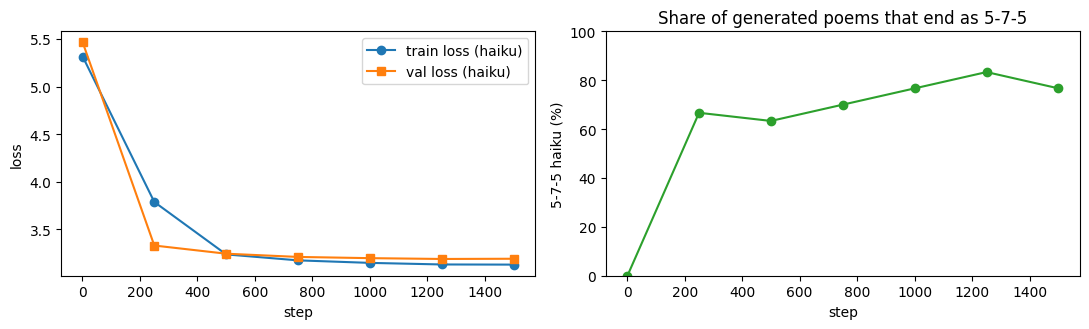

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(hist["step"], hist["loss"], "o-", label="train loss (haiku)")
ax[0].plot(hist["step"], hist["val"], "s-", label="val loss (haiku)")
ax[0].set_xlabel("step"); ax[0].set_ylabel("loss"); ax[0].legend()
ax[1].plot(hist["step"], hist["haiku"], "o-", color="tab:green")
ax[1].set_ylim(0, 100); ax[1].set_xlabel("step"); ax[1].set_ylabel("5-7-5 haiku (%)")
ax[1].set_title("Share of generated poems that end as 5-7-5")
plt.tight_layout(); plt.show()

## 11. 結果：LoRA の前・後・外したとき

同じ書き出し（俳句の検証用の句の最初の5音）から、次の3つで詠ませて、形の割合を比べます。

| モデル | 中身 |
|---|---|
| LoRA 学習前 | 事前学習の重み（新しい文字は元の文字の写し） |
| LoRA 学習後 | 事前学習の重み ＋ 学習した LoRA と新しい行・列 |
| LoRA を外す | 学習後から `A・B` だけを取り除く（新しい行・列は残す） |

さらに、**和歌の**書き出しで「LoRA を外す」と、元どおり和歌を詠めるかも確かめます。

俳句の書き出し（検証用の句の最初の5音、各2回）
  LoRA 学習前: 俳句   0%  和歌  96%  その他   4%
  LoRA 学習後: 俳句  76%  和歌   0%  その他  24%
  LoRA を外す: 俳句   0%  和歌  88%  その他  12%
和歌の書き出し（検証用の歌の最初の5音、各2回）
  LoRA 学習後: 俳句  82%  和歌   0%  その他  18%
  LoRA を外す: 俳句   0%  和歌  96%  その他   4%


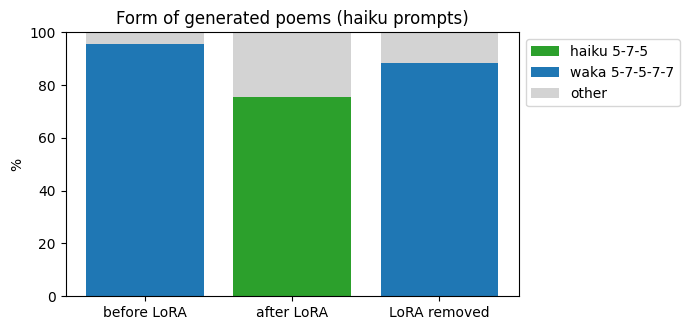

In [13]:
P_after = merged(L)
P_off = merged(L, use_lora=False)
rate_after = form_rates(P_after, haiku_val)
rate_off = form_rates(P_off, haiku_val)
waka_off = form_rates(P_off, waka_val[:60])
waka_after = form_rates(P_after, waka_val[:60])

print("俳句の書き出し（検証用の句の最初の5音、各2回）")
for name, rt in [("LoRA 学習前", rate_before), ("LoRA 学習後", rate_after), ("LoRA を外す", rate_off)]:
    print(f"  {name}: " + "  ".join(f"{LABEL[k]} {rt[k]:3.0f}%" for k in ("haiku", "waka", "other")))
print("和歌の書き出し（検証用の歌の最初の5音、各2回）")
for name, rt in [("LoRA 学習後", waka_after), ("LoRA を外す", waka_off)]:
    print(f"  {name}: " + "  ".join(f"{LABEL[k]} {rt[k]:3.0f}%" for k in ("haiku", "waka", "other")))

fig, ax = plt.subplots(figsize=(7, 3.4))
names = ["before LoRA", "after LoRA", "LoRA removed"]
rates = [rate_before, rate_after, rate_off]
bottom = np.zeros(3)
for k, col in [("haiku", "tab:green"), ("waka", "tab:blue"), ("other", "lightgray")]:
    vals = np.array([r[k] for r in rates])
    ax.bar(names, vals, bottom=bottom, color=col, label={"haiku": "haiku 5-7-5", "waka": "waka 5-7-5-7-7", "other": "other"}[k])
    bottom += vals
ax.set_ylabel("%"); ax.set_ylim(0, 100); ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title("Form of generated poems (haiku prompts)")
plt.tight_layout(); plt.show()

In [14]:
for i, segs in enumerate(haiku_val[:6]):
    print("原句        :", "／".join(segs))
    print("LoRA 学習前 :", show(generate(P_before, segs[0], seed=i)))
    print("LoRA 学習後 :", show(generate(P_after, segs[0], seed=i)))
    print()
for kana in ["はるかすみ", "ふるいけや", "なつくさや", "あきかぜの"]:
    print(f"【{kana}】 外す: {show(generate(P_off, kana, seed=1))}")
    print(f"{'':8s} 付ける: {show(generate(P_after, kana, seed=1))}")

原句        : ばせをばを／はしらにかけん／いほのつき
LoRA 学習前 : ばせをばを／たつたかへるる／かりにかへ／たたひのかせに／こひしかるるる   [和歌] 音数 5-7-5-7-7
LoRA 学習後 : ばせをばを／たてしかへるら／かぜみかな   [俳句] 音数 5-7-5

原句        : ほしざきの／やみをみよとや／なくちどり
LoRA 学習前 : ほしざきの／こゑにもいてそ／かけにける／いつかところも／おもほゆるかな   [和歌] 音数 5-7-5-7-7
LoRA 学習後 : ほしざきの／ころのやのしゅくもかりな   [その他] 音数 5-11

原句        : すそやまや／にじはくあとの／ゆふつつじ
LoRA 学習前 : すそやまや／いつのかはらに／おもふこと／おもふこころの／はるのよのつき   [和歌] 音数 5-7-5-7-7
LoRA 学習後 : すそやまや／いつのかつらき／うらたつゆ   [俳句] 音数 5-7-5

原句        : るすにきて／たなさがしする／ふぢのはな
LoRA 学習前 : るすにきて／あきのなからの／たかさこの／たまのはなとか／いまはしらゆき   [和歌] 音数 5-7-5-7-7
LoRA 学習後 : るすにきて／あさへのあはれ／たつたなく   [俳句] 音数 5-7-5

原句        : かしのきの／はなにかまはぬ／すがたかな
LoRA 学習前 : かしのきの／みねはあらしふ／なくなりの／はなをわかれの／たえぬへきかな   [和歌] 音数 5-7-5-7-7
LoRA 学習後 : かしのきの／はなをいのちは／なのときな   [俳句] 音数 5-7-5

原句        : さけのみに／かたらんかかる／たきのはな
LoRA 学習前 : さけのみに／たのめにあふに／あるものを／なほさかはつは／なからましもを   [和歌] 音数 5-7-5-7-7
LoRA 学習後 : さけのみに／なぎてしかはの／ありにしよ   [俳句] 音数 5-7-5

【はるかすみ】 外す: はるかすみ／かぜにもいげむ／さかりけり／いげたつかぜの／かぜをみるかな   [和歌] 音数 5-7-5-7-7
         付ける: はるかすみ／かりなるかは／かりともなく   [その他] 音数 5-6-6


### 濁点の字を使うようになったか

学習前は新しい文字の出力の列が 0 なので、濁点の字はほとんど出ません。
LoRA の学習後に、詠んだ詩の中で濁点・半濁点の字の割合が増えたかを数えます（俳句のデータでは約10%）。

なお「LoRA を外す」モデルにも、学習した新しい文字の行・列は残っています。そのため、和歌を詠みながら濁点の字を使うことがあります。

In [15]:
def dakuten_rate(P, prompts):
    text = "".join(generate(P, segs[0], seed=i)[len(segs[0]):] for i, segs in enumerate(prompts))
    kana = [c for c in text if c not in (SEP, END)]
    d = sum(1 for c in kana if unicodedata.normalize("NFD", c) != c)
    return 100 * d / max(1, len(kana))
data_rate = 100 * sum(1 for c in haiku_text_all if unicodedata.normalize("NFD", c) != c) / len(haiku_text_all.replace(SEP, "").replace(END, ""))
print(f"俳句のデータ: {data_rate:.1f}%")
print(f"LoRA 学習前: {dakuten_rate(P_before, haiku_val):.1f}%")
print(f"LoRA 学習後: {dakuten_rate(P_after, haiku_val):.1f}%")

俳句のデータ: 9.8%


LoRA 学習前: 0.0%


LoRA 学習後: 5.3%


## 12. 自由に入力して試す（入力欄）

下のセルを実行すると入力欄が出ます。最初の5音（または5＋7音）を**ひらがな**で入力すると、
**LoRA なし（和歌）** と **LoRA あり（俳句）** の両方で続きを詠みます。何も入力せずに Enter を押すと終了します。

- 俳句の読みは昔の仮名遣いで、**濁点あり**です（例：「なつくさや」「ふるいけや」）。
- 学習データにない文字は無視します。漢字は入力できません。

In [ ]:
N_CANDIDATES = 3
while True:
    kana = input("最初の部分（ひらがな。空のまま Enter で終了）> ")
    if not kana.strip():
        print("終了しました")
        break
    for k in range(N_CANDIDATES):
        print(f"  LoRA なし[{k + 1}]", show(generate(P_off, kana, TARGET_WAKA)))
        print(f"  LoRA あり[{k + 1}]", show(generate(P_after, kana, TARGET_HAIKU)))
    print()

## 13. （任意）LoRA の付け方を変えて比べる

LoRA を付ける行列と r を変えて学習し直し、俳句になった割合を比べます。
時間がかかるので、初期設定では実行しません。`RUN_COMPARE = True` にして実行してください（1条件 約1分）。

In [17]:
RUN_COMPARE = False
COMPARE = [(("Wq", "Wv"), 1), (("Wq", "Wv"), 4), (("Wq", "Wk", "Wv", "Wo"), 4), (("Wg", "Wu", "Wd"), 4)]

def train_lora_quiet(targets, rank, steps=LORA_STEPS):
    global LORA_TARGETS, LORA_RANK, LORA_SCALE
    saved = (LORA_TARGETS, LORA_RANK, LORA_SCALE)
    LORA_TARGETS, LORA_RANK, LORA_SCALE = targets, rank, LORA_ALPHA / rank
    Lx = init_lora(); st = {}; rg = np.random.default_rng(SEED)
    for step in range(1, steps + 1):
        lr = LORA_LR * min(1, step / 50) * (0.1 + 0.9 * 0.5 * (1 + np.cos(np.pi * step / steps)))
        P = merged(Lx)
        loss, cache = forward(P, *get_batch(haiku_tr, BATCH, rg), rng=rg, dropout=DROPOUT)
        adamw_step(Lx, lora_grads(Lx, backward(P, cache)), st, step, lr, decay_keys=set())
    rate = form_rates(merged(Lx), haiku_val)
    n = sum(Lx[t + s].size for t in targets for s in ("_A", "_B"))
    LORA_TARGETS, LORA_RANK, LORA_SCALE = saved
    return n, rate

if RUN_COMPARE:
    for targets, rank in COMPARE:
        t0 = time.time()
        n, rate = train_lora_quiet(targets, rank)
        print(f"{'+'.join(targets):14s} r={rank}: LoRA {n:6,} 個  俳句 {rate['haiku']:3.0f}%  和歌 {rate['waka']:3.0f}%  その他 {rate['other']:3.0f}%  ({time.time() - t0:.0f}秒)")
else:
    print("RUN_COMPARE = True にすると、LoRA の付け方ごとの結果を比べます。")

RUN_COMPARE = True にすると、LoRA の付け方ごとの結果を比べます。


## まとめ

- 事前学習のモデルは、俳句の書き出しを与えても **5句の和歌** を詠もうとした。
- 本体の重みを固定し、**LoRA（Wq・Wv、r=4、1,024 個）と新しい文字の行・列だけ**を約850句で学習すると、**3句で止まる俳句** を詠むようになった。
- **LoRA を外すと、元の和歌のモデルに戻る**。本体の重みは一度も変えていない。
- 新しい文字（濁点の字など）は、語彙を後ろに足し、入力側は元の字のベクトルを写し、出力側は 0 から始めた。実際の LLM に専門用語などの語彙を足すときも同じ考え方をする。
- 俳句にならなかった残り（その他）の多くは、途中で音数が 1 つずれたもの。1ブロック・約850句の小さな学習なので、言葉の意味が通る句にはならない。

### 実際の LLM の LoRA との対応
| この教材 | 実際の LLM |
|---|---|
| 1ブロック、`Wq`・`Wv` に r=4 | 数十ブロックの Attention（と MLP）に r=8〜64 |
| 学習する重みは約 4,900 個（本体の約7%） | 本体の 0.1〜1% 程度 |
| 新しい文字の行・列も学習 | 語彙を足すときは、Embedding と出力層の該当部分も学習する |
| `A・B` を外せば元に戻る | 1つの本体に、用途ごとの LoRA を差し替えて使える |

## やってみよう
| 変えるもの | 試すこと |
|---|---|
| `LORA_RANK = 1` | 1つの行列につき 128 個だけで、俳句になるか |
| `LORA_TARGETS = ('Wg','Wu','Wd')` | MLP に付けると違うか（13章でまとめて比べられる） |
| `LORA_STEPS = 300` | 学習を短くすると、どこまで俳句に寄るか |
| 入力欄 | 和歌らしい書き出し・俳句らしい書き出しで、LoRA なし／ありを比べる |

## 出典・ライセンス
- 和歌：[Wikisource](https://ja.wikisource.org/) の八代集（『古今』『後撰』『拾遺』『千載』『新古今』）。CC BY-SA 4.0。実行時に取得します。
- 俳句：松尾芭蕉『芭蕉俳句全集』大塚甲山 編（1903年）、[Wikisource](https://ja.wikisource.org/wiki/芭蕉俳句全集)。本文は CC BY-SA 4.0。
  **読みは AI（Claude Opus 5.5）が付けたもので、誤りを含む可能性があります。** `芭蕉俳句全集.txt` は同じ CC BY-SA 4.0 で提供します。
- 参考：Hu et al., *LoRA: Low-Rank Adaptation of Large Language Models* (2021)